In [1]:
include("GodunovMethod.jl")

MovingGridsDynamicStep (generic function with 1 method)

In [2]:
using DataFrames
using PrettyTables

γ = BigFloat("1.4")
ε = BigFloat("1e-15")

Tests = DataFrame(
    Test = Int8[],
    ρₗ = BigFloat[],
    uₗ = BigFloat[],
    pₗ = BigFloat[],
    ρᵣ = BigFloat[],
    uᵣ = BigFloat[],
    pᵣ = BigFloat[],
    t = BigFloat[]
)

push!(Tests, [1 BigFloat("1.0") BigFloat("0.0") BigFloat("1.0") BigFloat("0.125") BigFloat("0.0") BigFloat("0.1") BigFloat("0.25")])
push!(Tests, [2 BigFloat("1.0") BigFloat("-2.0") BigFloat("0.4") BigFloat("1.0") BigFloat("2.0") BigFloat("0.4") BigFloat("0.15")])
push!(Tests, [3 BigFloat("1.0") BigFloat("0.0") BigFloat("1000.0") BigFloat("1.0") BigFloat("0.0") BigFloat("0.01") BigFloat("0.012")])
push!(Tests, [4 BigFloat("1.0") BigFloat("0.0") BigFloat("0.01") BigFloat("1.0") BigFloat("0.0") BigFloat("100.0") BigFloat("0.035")])
push!(Tests, [5 BigFloat("5.99924") BigFloat("19.5975") BigFloat("460.894") BigFloat("5.99242") BigFloat("-6.19633") BigFloat("46.0950") BigFloat("0.035")])

pretty_table(Tests;
    formatters = [fmt__printf("%.5f", [2, 3, 4, 5, 6, 7, 8])],
    style = TextTableStyle(; table_border = crayon"yellow"),
    fit_table_in_display_horizontally = false,
)

┌──────┬──────────┬──────────┬────────────┬──────────┬──────────┬───────────┬──────────┐
│ Test │       ρₗ │       uₗ │         pₗ │       ρᵣ │       uᵣ │        pᵣ │        t │
│ Int8 │ BigFloat │ BigFloat │   BigFloat │ BigFloat │ BigFloat │  BigFloat │ BigFloat │
├──────┼──────────┼──────────┼────────────┼──────────┼──────────┼───────────┼──────────┤
│    1 │  1.00000 │  0.00000 │    1.00000 │  0.12500 │  0.00000 │   0.10000 │  0.25000 │
│    2 │  1.00000 │ -2.00000 │    0.40000 │  1.00000 │  2.00000 │   0.40000 │  0.15000 │
│    3 │  1.00000 │  0.00000 │ 1000.00000 │  1.00000 │  0.00000 │   0.01000 │  0.01200 │
│    4 │  1.00000 │  0.00000 │    0.01000 │  1.00000 │  0.00000 │ 100.00000 │  0.03500 │
│    5 │  5.99924 │ 19.59750 │  460.89400 │  5.99242 │ -6.19633 │  46.09500 │  0.03500 │
└──────┴──────────┴──────────┴────────────┴──────────┴──────────┴───────────┴──────────┘


In [ ]:
using Statistics
using Polynomials
using Plots

function loghloge(TestCase::Int64)

    default(:xlabel, "h")
    default(:legend, :bottomright)
    default(:xscale, :log10)
    default(:yscale, :log10)

    Wₗ = PrimVars(Tuple(Tests[TestCase, 2:4]))
    Wᵣ = PrimVars(Tuple(Tests[TestCase, 5:7]))
    t_max = Tests[TestCase, 8]
    max_h = BigFloat("0.04")
    min_h = BigFloat("0.01")

    CourantNumber = BigFloat("0.05")
    ε₁ = BigFloat("0.0002")
    ε₂ = BigFloat("0.0002")
    α = BigFloat("0.05")

    es = DataFrame(
        hs = BigFloat[],
        ρs_error = BigFloat[],
        us_error = BigFloat[],
        ps_error = BigFloat[],
        Es_error = BigFloat[]
    )

    es2 = DataFrame(
        hs = BigFloat[],
        ρs_error = BigFloat[],
        us_error = BigFloat[],
        ps_error = BigFloat[],
        Es_error = BigFloat[]
    )

    es3 = DataFrame(
        hs = BigFloat[],
        ρs_error = BigFloat[],
        us_error = BigFloat[],
        ps_error = BigFloat[],
        Es_error = BigFloat[]
    )

    function BCₗ(t::BigFloat)
        return Wₗ
    end

    function BCᵣ(t::BigFloat)
        return Wᵣ
    end

    function IC(x::BigFloat)
        return x ≥ 0 ? Wᵣ : Wₗ
    end

    for h in logrange(max_h, min_h, 3)

        println("$(Float64(h)):")

        println("    Non moving grid")

        xs = collect(BigFloat("-1.0"):h:BigFloat("1.0"))

        W = W⁺(Wₗ, Wᵣ, γ, ε)
        
        Ws = GodunovMethod(xs, γ, t_max, ε, IC, BCₗ, BCᵣ)

        ρs = sum(abs, getfield.(Ws, :ρ) - getfield.(W.(xs / t_max), :ρ))
        us = sum(abs, getfield.(Ws, :u) - getfield.(W.(xs / t_max), :u))
        ps = sum(abs, getfield.(Ws, :p) - getfield.(W.(xs / t_max), :p))
        Es = sum(abs, calculateEnergy.(Ws, γ) - calculateEnergy.(W.(xs / t_max), γ))

        push!(es, [h ρs*h us*h ps*h Es*h])

        println("    Moving grid")

        xs = collect(BigFloat("-1.0"):h:BigFloat("1.0"))

        Ws, ψs, xs = MovingGridsDynamicStep(xs, γ, t_max, ε, 
                        BigFloat("0.002"), BigFloat("0.0002"), BigFloat("0.005"), BigFloat("0.05"),
                        IC, BCₗ, BCᵣ, false)

        ρs = sum(abs, (getfield.(Ws, :ρ) - getfield.(W.((xs[2:end] - xs[1:end-1]) / t_max), :ρ))
                        .* (xs[2:end] - xs[1:end-1]) .* ψs)
        us = sum(abs, (getfield.(Ws, :u) - getfield.(W.((xs[2:end] - xs[1:end-1]) / t_max), :u))
                        .* (xs[2:end] - xs[1:end-1]) .* ψs)
        ps = sum(abs, (getfield.(Ws, :p) - getfield.(W.((xs[2:end] - xs[1:end-1]) / t_max), :p))
                        .* (xs[2:end] - xs[1:end-1]) .* ψs)
        Es = sum(abs, (calculateEnergy.(Ws, γ) - calculateEnergy.(W.((xs[2:end] - xs[1:end-1]) / t_max), γ))
                        .* (xs[2:end] - xs[1:end-1]) .* ψs)

        push!(es2, [h ρs us ps Es])

        println("    Moving with birth nodes")

        xs = collect(BigFloat("-1.0"):h:BigFloat("1.0"))

        Ws, ψs, xs = MovingGridsDynamicStep(xs, γ, t_max, ε, 
                        BigFloat("0.002"), BigFloat("0.0002"), BigFloat("0.005"), BigFloat("0.05"),
                        IC, BCₗ, BCᵣ, true)

        ρs = sum(abs, (getfield.(Ws, :ρ) - getfield.(W.((xs[2:end] - xs[1:end-1]) / t_max), :ρ))
                        .* (xs[2:end] - xs[1:end-1]) .* ψs)
        us = sum(abs, (getfield.(Ws, :u) - getfield.(W.((xs[2:end] - xs[1:end-1]) / t_max), :u))
                        .* (xs[2:end] - xs[1:end-1]) .* ψs)
        ps = sum(abs, (getfield.(Ws, :p) - getfield.(W.((xs[2:end] - xs[1:end-1]) / t_max), :p))
                        .* (xs[2:end] - xs[1:end-1]) .* ψs)
        Es = sum(abs, (calculateEnergy.(Ws, γ) - calculateEnergy.(W.((xs[2:end] - xs[1:end-1]) / t_max), γ))
                        .* (xs[2:end] - xs[1:end-1]) .* ψs)

        push!(es3, [h ρs us ps Es])
    end

    p1 = fit(log10.(es[!, :hs]), log10.(es[!, :ρs_error]), 1)[1]
    p1_text = string(round(Float64(p1), digits=4))

    p2 = fit(log10.(es[!, :hs]), log10.(es[!, :us_error]), 1)[1]
    p2_text = string(round(Float64(p2), digits=4))

    p3 = fit(log10.(es[!, :hs]), log10.(es[!, :ps_error]), 1)[1]
    p3_text = string(round(Float64(p3), digits=4))

    p4 = fit(log10.(es[!, :hs]), log10.(es[!, :Es_error]), 1)[1]
    p4_text = string(round(Float64(p4), digits=4))

    plot(
        plot(es[!, :hs], es[!, :ρs_error], ylabel="Density error", label="p = "*p1_text),
        plot(es[!, :hs], es[!, :us_error], ylabel="Velocity error", label="p = "*p2_text),
        plot(es[!, :hs], es[!, :ps_error], ylabel="Pressure error", label="p = "*p3_text),
        plot(es[!, :hs], es[!, :Es_error], ylabel="Internal energy error", label="p = "*p4_text),
        layout=(2,2),
        margin=5Plots.mm,
        size=(800,600)
    )

    p1 = fit(log10.(es2[!, :hs]), log10.(es2[!, :ρs_error]), 1)[1]
    p1_text = string(round(Float64(p1), digits=4))

    p2 = fit(log10.(es2[!, :hs]), log10.(es2[!, :us_error]), 1)[1]
    p2_text = string(round(Float64(p2), digits=4))

    p3 = fit(log10.(es2[!, :hs]), log10.(es2[!, :ps_error]), 1)[1]
    p3_text = string(round(Float64(p3), digits=4))

    p4 = fit(log10.(es2[!, :hs]), log10.(es2[!, :Es_error]), 1)[1]
    p4_text = string(round(Float64(p4), digits=4))

    plot!(es2[!, :hs], es2[!, :ρs_error], subplot=1, label="p = "*p1_text, c=:red)
    plot!(es2[!, :hs], es2[!, :us_error], subplot=2, label="p = "*p2_text, c=:red)
    plot!(es2[!, :hs], es2[!, :ps_error], subplot=3, label="p = "*p3_text, c=:red)
    plot!(es2[!, :hs], es2[!, :Es_error], subplot=4, label="p = "*p4_text, c=:red)

    p1 = fit(log10.(es3[!, :hs]), log10.(es3[!, :ρs_error]), 1)[1]
    p1_text = string(round(Float64(p1), digits=4))

    p2 = fit(log10.(es3[!, :hs]), log10.(es3[!, :us_error]), 1)[1]
    p2_text = string(round(Float64(p2), digits=4))

    p3 = fit(log10.(es3[!, :hs]), log10.(es3[!, :ps_error]), 1)[1]
    p3_text = string(round(Float64(p3), digits=4))

    p4 = fit(log10.(es3[!, :hs]), log10.(es3[!, :Es_error]), 1)[1]
    p4_text = string(round(Float64(p4), digits=4))

    plot!(es3[!, :hs], es3[!, :ρs_error], subplot=1, label="p = "*p1_text, c=:blue)
    plot!(es3[!, :hs], es3[!, :us_error], subplot=2, label="p = "*p2_text, c=:blue),
    plot!(es3[!, :hs], es3[!, :ps_error], subplot=3, label="p = "*p3_text, c=:blue)
    plot!(es3[!, :hs], es3[!, :Es_error], subplot=4, label="p = "*p4_text, c=:blue)
end

loghloge (generic function with 1 method)

0.04:
    Non moving grid
    Moving grid
      Moving grids simulation  1735    Time: 0:00:20 (11.90 ms/it)
       Minimum step: 0.04
    Moving with birth nodes
      Moving grids simulation  1843    Time: 0:00:19 (10.38 ms/it)
       Minimum step: 0.0025
0.02:
    Non moving grid
    Moving grid
      Moving grids simulation  3088    Time: 0:01:02 (20.28 ms/it)
       Minimum step: 0.02
    Moving with birth nodes
      Moving grids simulation  3257    Time: 0:01:29 (27.53 ms/it)
       Minimum step: 0.00015625
0.01:
    Non moving grid
    Moving grid
      Moving grids simulation  5222    Time: 0:03:54 (44.90 ms/it)
       Minimum step: 0.01
    Moving with birth nodes
      Moving grids simulation  5471    Time: 0:04:19 (47.44 ms/it)
       Minimum step: 0.00015625


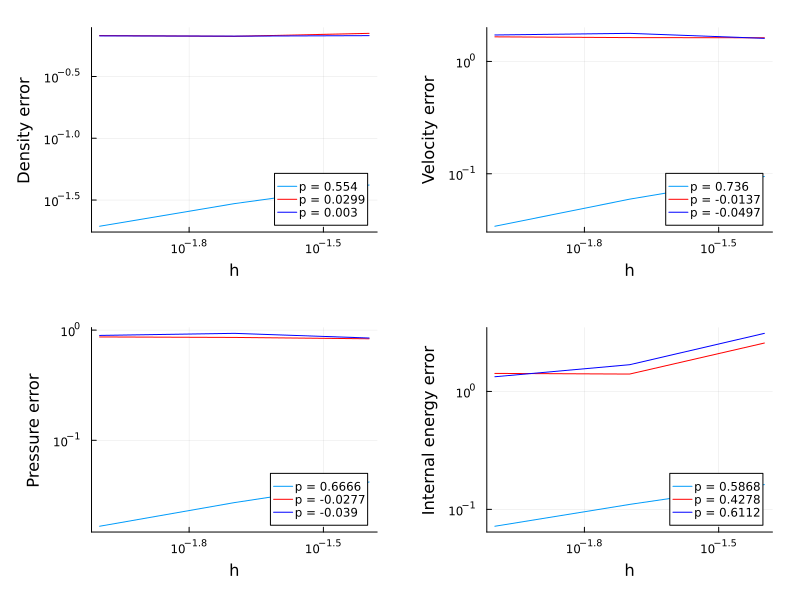

In [4]:
loghloge(1)